In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Data path
path = Path("../raw_data/pakistan_20261023_073030/pakistan_pm25_transformed.csv")
df = pd.read_csv(path)

# Datetime sort
df["datetime_from_utc"] = pd.to_datetime(df["datetime_from_utc"])
df = df.sort_values(by=["sensor_id", "datetime_from_utc"]).reset_index(drop=True)

# 1. Target: Agla 1 ghanta
df["target_pm25"] = df.groupby("sensor_id")["pm25_value"].shift(-1)

# 2. Lags: Pichle 1 aur 2 ghante
df["pm25_lag_1"] = df.groupby("sensor_id")["pm25_value"].shift(1)
df["pm25_lag_2"] = df.groupby("sensor_id")["pm25_value"].shift(2)

# 3. Momentum: Pichle 6 ghanton ka moving average
df["pm25_roll_mean_6h"] = df.groupby("sensor_id")["pm25_value"].transform(
    lambda x: x.rolling(window=6, min_periods=1).mean()
)

# 4. Time features
df["hour"] = df["datetime_from_utc"].dt.hour
df["month"] = df["datetime_from_utc"].dt.month
df["day_of_week"] = df["datetime_from_utc"].dt.dayofweek

# 5. Missing values fill (forward fill then backward fill)
cols_to_fill = ["pm25_value", "pm25_lag_1", "pm25_lag_2", "pm25_roll_mean_6h", "latitude", "longitude"]
df[cols_to_fill] = df.groupby("sensor_id")[cols_to_fill].ffill().bfill()

# Target ki missing rows drop (aakhri row jahan future nahi hai)
df = df[df["target_pm25"].notna()].copy()

print("Cleaned Dataset Shape:", df.shape)
df[["datetime_from_utc", "pm25_value", "pm25_lag_1", "pm25_roll_mean_6h", "target_pm25"]].head()

C:\Users\Abdul\AppData\Local\Temp\ipykernel_892\1379597477.py:8: DtypeWarning: Columns (24) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path)


Cleaned Dataset Shape: (133411, 37)


,datetime_from_utc,pm25_value,pm25_lag_1,pm25_roll_mean_6h,target_pm25
0,2024-03-24 23:00:00+00:00,122.0,122.0,122.000000,104.0
1,2024-03-25 00:00:00+00:00,104.0,122.0,113.000000,97.0
2,2024-03-25 01:00:00+00:00,97.0,104.0,107.666667,95.0
3,2024-03-25 02:00:00+00:00,95.0,97.0,104.500000,51.0
4,2024-03-25 03:00:00+00:00,51.0,95.0,93.800000,51.0


Correlation with target_pm25:
pm25_value           0.960402
pm25_lag_1           0.910433
pm25_roll_mean_6h    0.884162
pm25_lag_2           0.862120
longitude            0.215355
month                0.188408
hour                 0.069806
day_of_week         -0.007738
latitude            -0.043709
dtype: float64


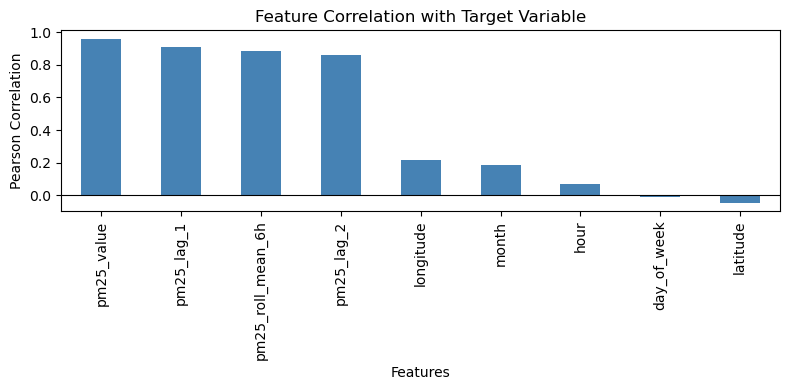

Selected Features: ['pm25_value', 'pm25_lag_1', 'pm25_roll_mean_6h', 'pm25_lag_2', 'longitude', 'month', 'hour']


In [2]:
# Candidate features list
features = [
    "pm25_value", "pm25_lag_1", "pm25_lag_2", "pm25_roll_mean_6h",
    "hour", "month", "day_of_week", "latitude", "longitude"
]

# Correlation with target
corr = df[features].corrwith(df["target_pm25"]).sort_values(ascending=False)
print("Correlation with target_pm25:")
print(corr)

# Simple Bar Plot
plt.figure(figsize=(8, 4))
corr.plot(kind="bar", color="steelblue")
plt.title("Feature Correlation with Target Variable")
plt.xlabel("Features")
plt.ylabel("Pearson Correlation")
plt.axhline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

# Selecting features having correlation >= 0.05
selected_features = corr[abs(corr) >= 0.05].index.tolist()
print("Selected Features:", selected_features)

In [3]:
# ==============================================================================
# Step 3: Feature Selection and Train-Test Split (Chronological)
# ==============================================================================

# 1. Final selected features list (Weak features excluded)
selected_features = [
    "pm25_value",
    "pm25_lag_1",
    "pm25_lag_2",
    "pm25_roll_mean_6h",
    "hour",
    "month",
    "latitude",
    "longitude"
]

# 2. X (Features) aur y (Target) alag karein
X = df[selected_features]
y = df["target_pm25"]

# 3. 80% Train aur 20% Held-Out Test Split (Time-based split, no shuffle)
split_index = int(len(df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Train-Test Split Summary:")
print("Training set shape:", X_train.shape)
print("Testing set shape :", X_test.shape)
print("Features used     :", list(X.columns))

Train-Test Split Summary:
Training set shape: (106728, 8)
Testing set shape : (26683, 8)
Features used     : ['pm25_value', 'pm25_lag_1', 'pm25_lag_2', 'pm25_roll_mean_6h', 'hour', 'month', 'latitude', 'longitude']


In [4]:
# ==============================================================================
# Model 1: Baseline Ridge Regression
# ==============================================================================
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np

# 1. Pipeline: Pehle data scale hoga, phir Ridge model train hoga
ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=1.0))
])

# 2. Train the model
ridge_pipeline.fit(X_train, y_train)

# 3. Test data par prediction
y_pred_ridge = ridge_pipeline.predict(X_test)

# 4. Evaluation Metrics
r2_ridge = r2_score(y_test, y_pred_ridge)
rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
mae_ridge = mean_absolute_error(y_test, y_pred_ridge)

print("--- Model 1: Ridge Regression Results ---")
print(f"R2 Score : {r2_ridge:.4f}")
print(f"RMSE     : {rmse_ridge:.2f} ug/m3")
print(f"MAE      : {mae_ridge:.2f} ug/m3")

--- Model 1: Ridge Regression Results ---
R2 Score : 0.9150
RMSE     : 26.00 ug/m3
MAE      : 14.88 ug/m3


In [5]:
# ==============================================================================
# Model 2: Support Vector Regression (LinearSVR)
# ==============================================================================
from sklearn.svm import LinearSVR

# 1. Pipeline: Scaler + LinearSVR
svr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearSVR(random_state=42, max_iter=2000))
])

# 2. Train the model
svr_pipeline.fit(X_train, y_train)

# 3. Test data par prediction
y_pred_svr = svr_pipeline.predict(X_test)

# 4. Evaluation Metrics
r2_svr = r2_score(y_test, y_pred_svr)
rmse_svr = np.sqrt(mean_squared_error(y_test, y_pred_svr))
mae_svr = mean_absolute_error(y_test, y_pred_svr)

print("--- Model 2: LinearSVR Results ---")
print(f"R2 Score : {r2_svr:.4f}")
print(f"RMSE     : {rmse_svr:.2f} ug/m3")
print(f"MAE      : {mae_svr:.2f} ug/m3")

--- Model 2: LinearSVR Results ---
R2 Score : 0.9129
RMSE     : 26.31 ug/m3
MAE      : 14.57 ug/m3


In [6]:
# ==============================================================================
# Model 3: Random Forest Regressor
# ==============================================================================
from sklearn.ensemble import RandomForestRegressor

# 1. Random Forest Model
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

# 2. Train the model
rf_model.fit(X_train, y_train)

# 3. Test data par prediction
y_pred_rf = rf_model.predict(X_test)

# 4. Evaluation Metrics
r2_rf = r2_score(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
mae_rf = mean_absolute_error(y_test, y_pred_rf)

print("--- Model 3: Random Forest Results ---")
print(f"R2 Score : {r2_rf:.4f}")
print(f"RMSE     : {rmse_rf:.2f} ug/m3")
print(f"MAE      : {mae_rf:.2f} ug/m3")

--- Model 3: Random Forest Results ---
R2 Score : 0.9248
RMSE     : 24.45 ug/m3
MAE      : 13.53 ug/m3


In [7]:
# ==============================================================================
# Model 4: HistGradientBoostingRegressor
# ==============================================================================
from sklearn.ensemble import HistGradientBoostingRegressor

# 1. HistGradientBoosting Model
hgb_model = HistGradientBoostingRegressor(
    max_iter=100,
    learning_rate=0.1,
    random_state=42
)

# 2. Train the model
hgb_model.fit(X_train, y_train)

# 3. Test data par prediction
y_pred_hgb = hgb_model.predict(X_test)

# 4. Evaluation Metrics
r2_hgb = r2_score(y_test, y_pred_hgb)
rmse_hgb = np.sqrt(mean_squared_error(y_test, y_pred_hgb))
mae_hgb = mean_absolute_error(y_test, y_pred_hgb)

print("--- Model 4: HistGradientBoosting Results ---")
print(f"R2 Score : {r2_hgb:.4f}")
print(f"RMSE     : {rmse_hgb:.2f} ug/m3")
print(f"MAE      : {mae_hgb:.2f} ug/m3")

--- Model 4: HistGradientBoosting Results ---
R2 Score : 0.9279
RMSE     : 23.94 ug/m3
MAE      : 13.33 ug/m3


--- Models Comparison Table ---


,Model,R2 Score,RMSE (ug/m3),MAE (ug/m3)
0,Ridge Regression,0.914995,25.996008,14.876396
1,LinearSVR,0.912944,26.307749,14.574035
2,Random Forest,0.924806,24.449856,13.525820
3,HistGradientBoosting,0.927889,23.943382,13.330567


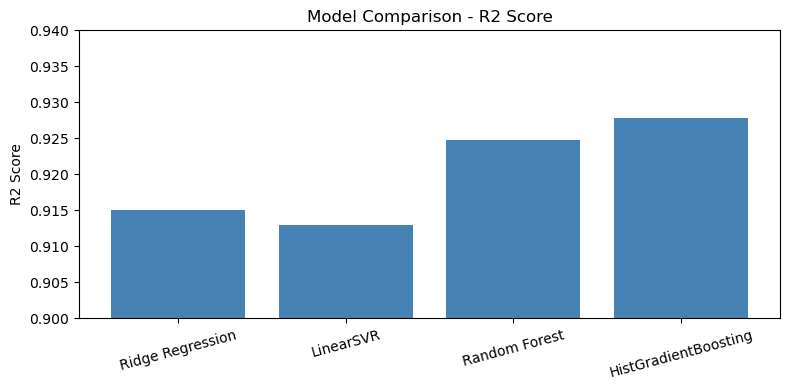

In [8]:
# ==============================================================================
# Step 8: Models Comparison Summary
# ==============================================================================

# Dataframe of all 4 models
results_df = pd.DataFrame({
    "Model": ["Ridge Regression", "LinearSVR", "Random Forest", "HistGradientBoosting"],
    "R2 Score": [r2_ridge, r2_svr, r2_rf, r2_hgb],
    "RMSE (ug/m3)": [rmse_ridge, rmse_svr, rmse_rf, rmse_hgb],
    "MAE (ug/m3)": [mae_ridge, mae_svr, mae_rf, mae_hgb]
})

print("--- Models Comparison Table ---")
display(results_df)

# Simple Bar Chart Comparison (R2 Score)
plt.figure(figsize=(8, 4))
plt.bar(results_df["Model"], results_df["R2 Score"], color="steelblue")
plt.ylim(0.90, 0.94)
plt.title("Model Comparison - R2 Score")
plt.ylabel("R2 Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [9]:
# ==============================================================================
# Step 9: End-to-End Pipeline with GridSearchCV and TimeSeriesSplit
# ==============================================================================
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

# 1. Full Pipeline
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", HistGradientBoostingRegressor(random_state=42))
])

# 2. Hyperparameter Grid (Koshish karein ke 4-6 combinations hon taake jaldi run ho)
param_grid = {
    "model__learning_rate": [0.05, 0.1],
    "model__max_iter": [100, 150],
    "model__min_samples_leaf": [20, 50]
}

# 3. TimeSeriesSplit (3 splits for time-series cross-validation)
tscv = TimeSeriesSplit(n_splits=3)

# 4. GridSearchCV
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=tscv,
    scoring="r2",
    n_jobs=-1
)

print("Starting Hyperparameter Tuning...")
grid_search.fit(X_train, y_train)

# 5. Best Model and Evaluation
best_pipeline = grid_search.best_estimator_

print("\n--- Tuning Complete ---")
print("Best Parameters:", grid_search.best_params_)
print(f"Best CV Score (R2): {grid_search.best_score_:.4f}")

# 6. Final Evaluation on Held-Out Test Set
y_pred_final = best_pipeline.predict(X_test)
final_r2 = r2_score(y_test, y_pred_final)
final_rmse = np.sqrt(mean_squared_error(y_test, y_pred_final))
final_mae = mean_absolute_error(y_test, y_pred_final)

print("\n--- Final Tuned Model on Held-Out Test Set ---")
print(f"Final R2 Score : {final_r2:.4f}")
print(f"Final RMSE     : {final_rmse:.2f} ug/m3")
print(f"Final MAE      : {final_mae:.2f} ug/m3")

Starting Hyperparameter Tuning...

--- Tuning Complete ---
Best Parameters: {'model__learning_rate': 0.05, 'model__max_iter': 150, 'model__min_samples_leaf': 50}
Best CV Score (R2): 0.9402

--- Final Tuned Model on Held-Out Test Set ---
Final R2 Score : 0.9282
Final RMSE     : 23.89 ug/m3
Final MAE      : 13.32 ug/m3


In [10]:
import joblib
# 1. 'models' folder banayein agar exist nahi karta
models_dir = Path("../models") if Path("../models").exists() or Path("../raw_data").exists() else Path("models")
models_dir.mkdir(parents=True, exist_ok=True)
model_path = models_dir / "best_pm25_pipeline.joblib"
# 2. Save the trained pipeline
joblib.dump(best_pipeline, model_path)
print(f"Model saved successfully at: {model_path}")
# 3. Test Loading (Tasdeeq karein ke model load ho raha hai)
loaded_model = joblib.load(model_path)
print("Model test load successful! Ready for production deployment.")

Model saved successfully at: ..\models\best_pm25_pipeline.joblib
Model test load successful! Ready for production deployment.


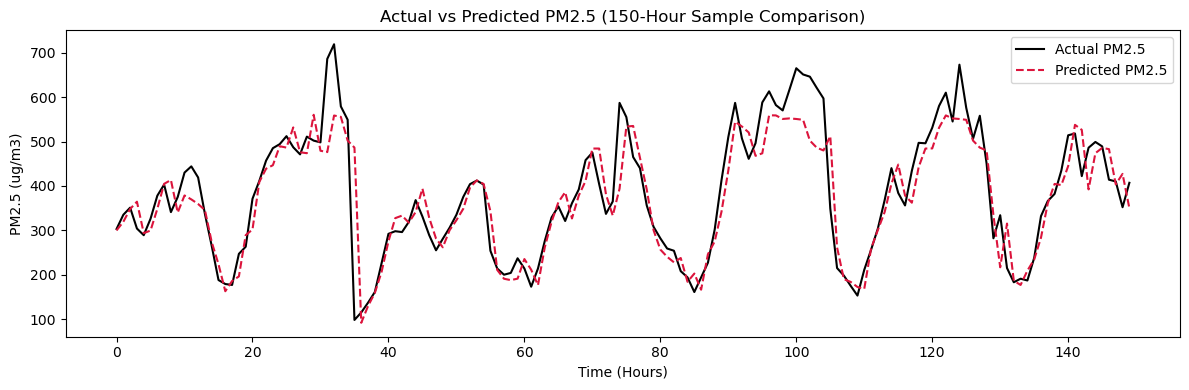

In [11]:
plt.figure(figsize=(12, 4))
plt.plot(y_test.values[:150], label="Actual PM2.5", color="black", linewidth=1.5)
plt.plot(y_pred_final[:150], label="Predicted PM2.5", color="crimson", linestyle="--", linewidth=1.5)
plt.title("Actual vs Predicted PM2.5 (150-Hour Sample Comparison)")
plt.xlabel("Time (Hours)")
plt.ylabel("PM2.5 (ug/m3)")
plt.legend()
plt.tight_layout()
plt.show()

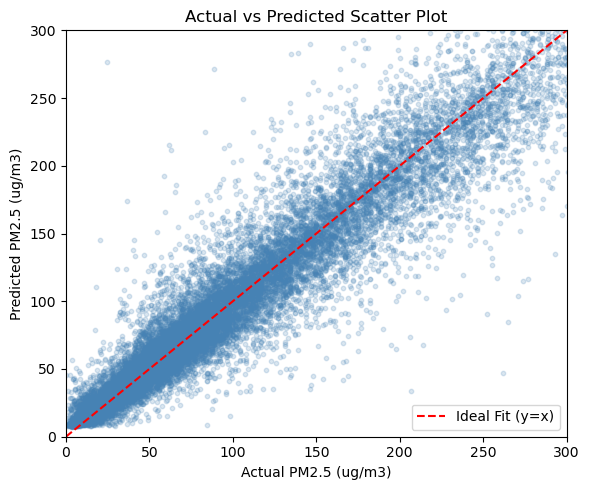

In [12]:
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred_final, alpha=0.2, color="steelblue", s=10)
plt.plot([0, 300], [0, 300], color="red", linestyle="--", label="Ideal Fit (y=x)")
plt.xlim(0, 300)
plt.ylim(0, 300)
plt.title("Actual vs Predicted Scatter Plot")
plt.xlabel("Actual PM2.5 (ug/m3)")
plt.ylabel("Predicted PM2.5 (ug/m3)")
plt.legend()
plt.tight_layout()
plt.show()

In [13]:
# ==============================================================================
# Step 1: Imports and Hardware Check
# ==============================================================================
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import optuna
import mlflow
import mlflow.pytorch

# Check hardware (GPU or CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
print("PyTorch Version:", torch.__version__)

Using device: cpu
PyTorch Version: 2.14.1+cpu


In [14]:
# ==============================================================================
# Step 2: Feature Scaling & PyTorch Tensor Conversion
# ==============================================================================
from sklearn.preprocessing import StandardScaler

# 1. Scaling the features (Mean=0, Variance=1)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. Convert NumPy Arrays to PyTorch Float Tensors
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)

X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1)

print("Tensors Ready!")
print("X_train Tensor Shape:", X_train_tensor.shape)
print("y_train Tensor Shape:", y_train_tensor.shape)

Tensors Ready!
X_train Tensor Shape: torch.Size([106728, 8])
y_train Tensor Shape: torch.Size([106728, 1])


In [15]:
# ==============================================================================
# Step 3: PyTorch TensorDataset & DataLoader (Mini-Batching)
# ==============================================================================
from torch.utils.data import TensorDataset, DataLoader

# 1. Combine X and y into a Dataset
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

# 2. DataLoader: 512 rows ke batches banayein
BATCH_SIZE = 512
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print("DataLoader Created Successfully!")
print(f"Total Batches in Training: {len(train_loader)} (Har batch mein {BATCH_SIZE} rows hain)")

DataLoader Created Successfully!
Total Batches in Training: 209 (Har batch mein 512 rows hain)


In [16]:
# ==============================================================================
# Step 4: Configurable PyTorch Neural Network Architecture
# ==============================================================================
import torch.nn as nn

class PM25NeuralNet(nn.Module):
    def __init__(self, input_dim=8, hidden_dim=128, dropout_rate=0.2):
        super(PM25NeuralNet, self).__init__()
        
        # 3-Layer Deep Neural Network
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            
            nn.Linear(hidden_dim // 2, 1)  # Final Output: 1 Predicted PM2.5 value
        )
        
    def forward(self, x):
        return self.network(x)

# Architecture check (Demo test to verify structure)
test_model = PM25NeuralNet(input_dim=8)
print("Model Architecture Created:")
print(test_model)

Model Architecture Created:
PM25NeuralNet(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [17]:
# ==============================================================================
# Step 5 (Fixed): Baseline PyTorch Training with Safe MLflow Tracking
# ==============================================================================
import torch.optim as optim

# 1. Purana agar koi MLflow run khula reh gaya ho to band karein
mlflow.end_run()

# 2. Experiment set karein
mlflow.set_experiment("AirPulse_PM25_PyTorch")

# 3. Device check
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 4. Model, Loss, Optimizer
model = PM25NeuralNet(input_dim=8, hidden_dim=128, dropout_rate=0.2).to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.003)

# 5. Safe MLflow Run
with mlflow.start_run(run_name="Baseline_PyTorch_Run"):
    mlflow.log_param("hidden_dim", 128)
    mlflow.log_param("lr", 0.003)
    mlflow.log_param("epochs", 5)
    
    print("Training started on", device)
    for epoch in range(1, 6):
        model.train()
        total_loss = 0.0
        
        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            
            optimizer.zero_grad()
            preds = model(batch_x)
            loss = criterion(preds, batch_y)
            loss.backward()
            optimizer.step()
            
            total_loss += loss.item()
            
        avg_loss = total_loss / len(train_loader)
        mlflow.log_metric("train_mse_loss", avg_loss, step=epoch)
        print(f"Epoch [{epoch}/5] - Loss (MSE): {avg_loss:.2f}")

    print("Baseline Training Complete and Logged to MLflow!")

Training started on cpu
Epoch [1/5] - Loss (MSE): 4715.37
Epoch [2/5] - Loss (MSE): 1023.64
Epoch [3/5] - Loss (MSE): 942.99
Epoch [4/5] - Loss (MSE): 919.60
Epoch [5/5] - Loss (MSE): 904.23
Baseline Training Complete and Logged to MLflow!


In [18]:
# ==============================================================================
# Step 6: Optuna Objective Function with Nested MLflow Tracking
# ==============================================================================
import optuna

def objective(trial):
    # 1. Optuna suggests hyperparameters
    hidden_dim = trial.suggest_categorical("hidden_dim", [64, 128, 256])
    lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)
    dropout_rate = trial.suggest_float("dropout_rate", 0.1, 0.4)
    epochs = 4  # Quick 4 epochs per trial for fast CPU search
    
    # 2. Build model with suggested parameters
    model = PM25NeuralNet(input_dim=8, hidden_dim=hidden_dim, dropout_rate=dropout_rate).to(device)
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    
    # 3. Log each trial inside MLflow as a child run
    with mlflow.start_run(run_name=f"Trial_{trial.number}", nested=True):
        mlflow.log_params({
            "hidden_dim": hidden_dim,
            "lr": lr,
            "dropout_rate": dropout_rate
        })
        
        # Training loop
        model.train()
        for epoch in range(epochs):
            for batch_x, batch_y in train_loader:
                batch_x, batch_y = batch_x.to(device), batch_y.to(device)
                optimizer.zero_grad()
                loss = criterion(model(batch_x), batch_y)
                loss.backward()
                optimizer.step()
        
        # 4. Validation on Test Data
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for batch_x, batch_y in test_loader:
                batch_x, batch_y = batch_x.to(device), batch_y.to(device)
                val_loss += criterion(model(batch_x), batch_y).item()
                
        val_rmse = np.sqrt(val_loss / len(test_loader))
        mlflow.log_metric("val_rmse", val_rmse)
        
    return val_rmse

print("Optuna Objective Function Defined Successfully!")

Optuna Objective Function Defined Successfully!


In [20]:
# ==============================================================================
# Step 7 (Robust): Run Optuna Study with Safe MLflow Parent/Child Runs
# ==============================================================================

# 1. Ensure any dangling MLflow run is safely closed first
mlflow.end_run()

# 2. Set experiment
mlflow.set_experiment("AirPulse_PM25_PyTorch")

# 3. Create Optuna Study
study = optuna.create_study(direction="minimize")

# 4. Run Study inside Parent MLflow Run
print("Starting Optuna 10-Trial Search on CPU...")

with mlflow.start_run(run_name="Optuna_Hyperparameter_Search"):
    study.optimize(objective, n_trials=10)
    
    # Log Best parameters to MLflow
    mlflow.log_params(study.best_params)
    mlflow.log_metric("best_val_rmse", study.best_value)

print("\n" + "=" * 55)
print("OPTUNA SEARCH COMPLETED SUCCESSFULLY! 🎉")
print("=" * 55)
print(f"Lowest Validation RMSE : {study.best_value:.2f} ug/m3")
print("\nBest Discovered Hyperparameters:")
for param, val in study.best_params.items():
    print(f"  • {param}: {val}")

[I 2026-10-23 19:48:54,296] A new study created in memory with name: no-name-9e9f4f98-f9df-4c71-9027-70907f863d40


Starting Optuna 10-Trial Search on CPU...


[I 2026-10-23 19:49:12,577] Trial 0 finished with value: 25.72129520477022 and parameters: {'hidden_dim': 128, 'lr': 0.0015238231709030156, 'dropout_rate': 0.17666113286369692}. Best is trial 0 with value: 25.72129520477022.
[I 2026-10-23 19:49:33,350] Trial 1 finished with value: 26.857480382688024 and parameters: {'hidden_dim': 64, 'lr': 0.0019516829243447916, 'dropout_rate': 0.3360507153436074}. Best is trial 0 with value: 25.72129520477022.
[I 2026-10-23 19:49:54,490] Trial 2 finished with value: 25.53931148820751 and parameters: {'hidden_dim': 256, 'lr': 0.0018151291871168667, 'dropout_rate': 0.30589575509858397}. Best is trial 2 with value: 25.53931148820751.
[I 2026-10-23 19:50:23,501] Trial 3 finished with value: 25.734232887003014 and parameters: {'hidden_dim': 256, 'lr': 0.0013307328635508821, 'dropout_rate': 0.36327759053201425}. Best is trial 2 with value: 25.53931148820751.
[I 2026-10-23 19:50:45,396] Trial 4 finished with value: 45.67236337949799 and parameters: {'hidden_


OPTUNA SEARCH COMPLETED SUCCESSFULLY! 🎉
Lowest Validation RMSE : 25.54 ug/m3

Best Discovered Hyperparameters:
  • hidden_dim: 256
  • lr: 0.0018151291871168667
  • dropout_rate: 0.30589575509858397


In [22]:
import torch.optim as optim
from sklearn.metrics import r2_score, mean_squared_error

# 1. Close any open run and set experiment
mlflow.end_run()
mlflow.set_experiment("AirPulse_PM25_PyTorch")

# 2. Extract best parameters from Optuna study
best_hidden = study.best_params["hidden_dim"]
best_lr = study.best_params["lr"]
best_dropout = study.best_params["dropout_rate"]
epochs = 10

# 3. Initialize final model with best architecture
final_model = PM25NeuralNet(
    input_dim=8, 
    hidden_dim=best_hidden, 
    dropout_rate=best_dropout
).to(device)

criterion = nn.MSELoss()
optimizer = optim.Adam(final_model.parameters(), lr=best_lr)

# 4. Train and Log Final Model to MLflow
with mlflow.start_run(run_name="Best_PyTorch_Final_Model"):
    # Log parameters
    mlflow.log_params(study.best_params)
    mlflow.log_param("epochs", epochs)
    
    print("Training final PyTorch model for 10 epochs...")
    for epoch in range(1, epochs + 1):
        final_model.train()
        total_train_loss = 0.0
        
        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            optimizer.zero_grad()
            preds = final_model(batch_x)
            loss = criterion(preds, batch_y)
            loss.backward()
            optimizer.step()
            total_train_loss += loss.item()
            
        avg_train_loss = total_train_loss / len(train_loader)
        mlflow.log_metric("train_mse_loss", avg_train_loss, step=epoch)
        print(f"Epoch [{epoch}/{epochs}] - Train MSE Loss: {avg_train_loss:.2f}")

    # 5. Evaluate on Test Set
    final_model.eval()
    all_preds = []
    all_targets = []
    
    with torch.no_grad():
        for batch_x, batch_y in test_loader:
            batch_x = batch_x.to(device)
            preds = final_model(batch_x)
            all_preds.extend(preds.cpu().numpy().flatten())
            all_targets.extend(batch_y.numpy().flatten())
            
    all_preds = np.array(all_preds)
    all_targets = np.array(all_targets)
    
    test_rmse = np.sqrt(mean_squared_error(all_targets, all_preds))
    test_r2 = r2_score(all_targets, all_preds)
    
    # Log test metrics to MLflow
    mlflow.log_metric("test_rmse", test_rmse)
    mlflow.log_metric("test_r2", test_r2)
    
    # 6. Log the PyTorch model with pickle serialization & sample input
    sample_input = np.zeros((1, 8), dtype=np.float32)
    mlflow.pytorch.log_model(
        pytorch_model=final_model,
        artifact_path="best_pytorch_model",
        serialization_format="pickle",
        input_example=sample_input
    )

    print("\n-------------------------------------------")
    print("Final Model Training & Evaluation Complete:")
    print(f"Test RMSE : {test_rmse:.2f} ug/m3")
    print(f"Test R2   : {test_r2:.4f}")
    print("Model artifact successfully saved to MLflow!")
    print("-------------------------------------------")

Training final PyTorch model for 10 epochs...
Epoch [1/10] - Train MSE Loss: 4420.53
Epoch [2/10] - Train MSE Loss: 1023.30
Epoch [3/10] - Train MSE Loss: 936.53
Epoch [4/10] - Train MSE Loss: 911.15
Epoch [5/10] - Train MSE Loss: 900.02
Epoch [6/10] - Train MSE Loss: 885.18
Epoch [7/10] - Train MSE Loss: 881.62
Epoch [8/10] - Train MSE Loss: 878.40
Epoch [9/10] - Train MSE Loss: 879.58
Epoch [10/10] - Train MSE Loss: 862.64


2026/10/23 20:02:17 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/23 20:02:17 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.



-------------------------------------------
Final Model Training & Evaluation Complete:
Test RMSE : 25.57 ug/m3
Test R2   : 0.9178
Model artifact successfully saved to MLflow!
-------------------------------------------
